In [ ]:
import numpy as np
#std = sqrt(mean(abs(x - x.mean())**2)).

a = np.array([[1, 2], [3, 4]])
print (np.std(a))
print (np.std(a, axis=0))
print (np.std(a, axis=1))

1.118033988749895
[1. 1.]
[0.5 0.5]


In [ ]:
#SNR
import numpy as np
def signaltonoise(a, axis=0, ddof=0):
    a = np.asanyarray(a)
    m = a.mean(axis)
    sd = a.std(axis=axis, ddof=ddof)
    return np.where(sd == 0, 0, m/sd)

Arr = [[20, 4, 7, 1, 34], [50, 12, 15, 34, 5]]
singleChannel = Arr
try:
    singleChannel = np.sum(Arr, axis=1)
    print ("# Single channel: ")
    print (singleChannel)
except:
    # was mono after all
    pass
print ("# np.amax(singleChannel)")
print (np.amax(singleChannel))
print ("# -1 * np.amin(singleChannel)")
print (-1 * np.amin(singleChannel))
norm = singleChannel / (max(np.amax(singleChannel), -1 * np.amin(singleChannel)))
print ("# Norm")
print (norm)
snr = signaltonoise(norm, axis=0, ddof=0)
print ("# Signal to Noise Ratio: ")
print (snr)

# Single channel: 
[ 66 116]
# np.amax(singleChannel)
116
# -1 * np.amin(singleChannel)
-66
# Norm
[0.56896552 1.        ]
# Signal to Noise Ratio: 
3.6400000000000006


In [ ]:
#KDE
from sklearn.neighbors import KernelDensity
import numpy as np
import matplotlib.pyplot as plt

X = np.array([[-1, -1], [-2, -1], [-3, -2], [1, 1], [2, 1], [3, 2]])

bandwidths = [0.1, 0.2, 0.3, 0.4, 0.5]
for bd in bandwidths:
    kde = KernelDensity(kernel='gaussian', bandwidth=bd).fit(X)
    scores = np.array(kde.score_samples(X))
    print ("# bandwidth : "+str(bd))
    print (scores)



# bandwidth : 0.1
[0.97553365 0.97553365 0.97553365 0.97553365 0.97553365 0.97553365]
# bandwidth : 0.2
[-0.41075698 -0.41075698 -0.41076071 -0.41075698 -0.41075698 -0.41076071]
# bandwidth : 0.3
[-1.21783246 -1.21781757 -1.22167598 -1.21783246 -1.21781757 -1.22167598]
# bandwidth : 0.4
[-1.75405584 -1.75220849 -1.79512632 -1.75405584 -1.75220849 -1.79512632]
# bandwidth : 0.5
[-2.11637408 -2.10041055 -2.22514766 -2.11637408 -2.10041055 -2.22514766]


In [ ]:
ls /Users/mac/Documents/proposal_training_heartbeat/course1/datasets/pascal/normal/

101_1305030823364_B.wav    172_1307971284351_A.wav
101_1305030823364_E.wav    172_1307971284351_B.wav
103_1305031931979_B.wav    172_1307971284351_B1.wav
103_1305031931979_D1.wav   173_1307973611151_B 2.wav
103_1305031931979_D2.wav   173_1307973611151_B.wav
103_1305031931979_D3.wav   173_1307973611151_C.wav
104_1305032492469_A.wav    173_1307973611151_C1.wav
105_1305033453095_A.wav    174_1307987737137_B.wav
105_1305033453095_C.wav    174_1307987737137_B1.wav
106_1306776721273_A.wav    175_1307987962616_B.wav
106_1306776721273_B1.wav   175_1307987962616_B1.wav
106_1306776721273_C1.wav   175_1307987962616_D.wav
106_1306776721273_C2.wav   176_1307988171173_A.wav
106_1306776721273_D1.wav   176_1307988171173_B.wav
106_1306776721273_D2.wav   176_1307988171173_B1.wav
107_1305654946865_A.wav    176_1307988171173_D.wav
107_1305654946865_C1.wav   177_1307989650056_A1.wav
108_1305654420093_A.wav    177_1307989650056_B.wav
108_1305654420093_B.wav    177_1307989650056_D.wav
109_1305653646620_A.wav

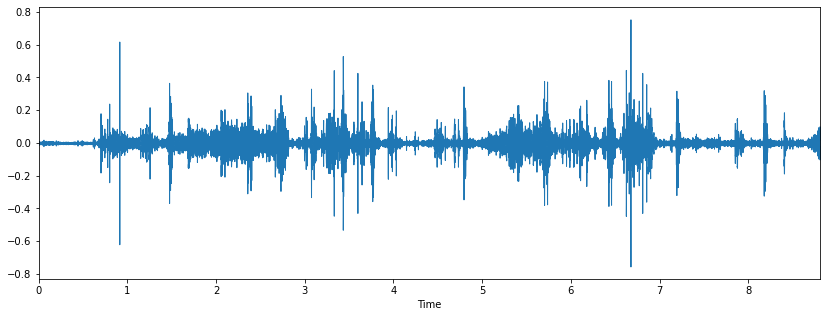

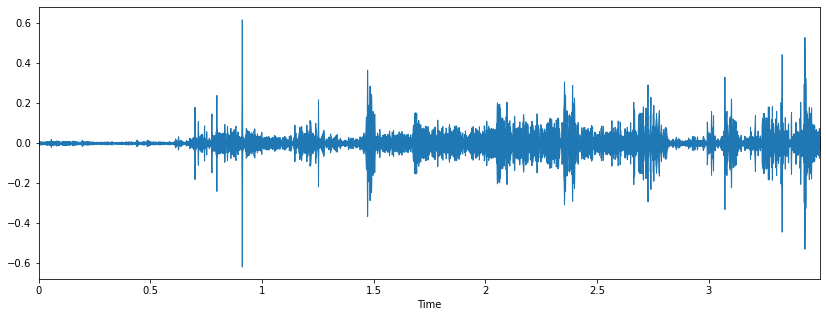

In [ ]:
#Normal heartbeat SOUND
import librosa
import matplotlib.pyplot as plt
import librosa.display
import IPython.display as ipd
import numpy as np

file_source = '/Users/mac/Documents/proposal_training_heartbeat/course1/datasets/pascal/normal/101_1305030823364_B.wav'
signal, sample_rate = librosa.load(file_source)
plt.figure(figsize=(14, 5))
librosa.display.waveplot(signal, sr=sample_rate)
plt.show()

signal = signal[0:int(3.5 * sample_rate)]  # Keep the first 3.5 seconds
plt.figure(figsize=(14, 5))
librosa.display.waveplot(signal, sr=sample_rate)
plt.show()

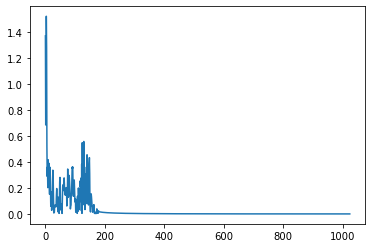

In [ ]:

n_fft = 2048
D = np.abs(librosa.stft(signal[:n_fft], n_fft=n_fft, hop_length=n_fft+1))
plt.plot(D);

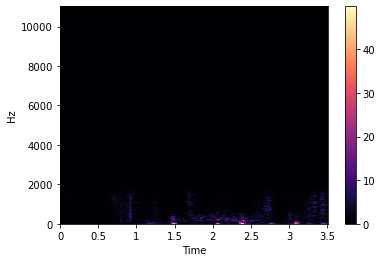

In [ ]:
#Now let’s take the complete signal, separate it to time windows,
#and apply the Fourier Transform on each time window.
#The number of samples between successive frames, e.g.,
#the columns of a spectrogram. This is denoted as a positive integer hop_length

hop_length = 512
D = np.abs(librosa.stft(signal, n_fft=n_fft,  hop_length=hop_length))
librosa.display.specshow(D, sr=sample_rate, x_axis='time', y_axis='linear');
plt.colorbar();

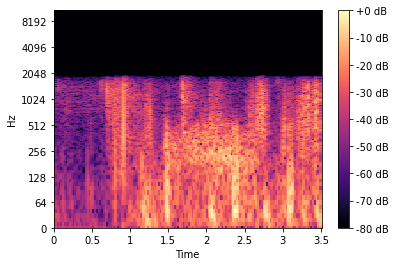

In [ ]:
#Wow can’t see much here can we?
#It’s because most sounds humans hear are concentrated in very small frequency and amplitude ranges.
#Let’s make another small adjustment - transform both the y-axis (frequency) to log scale,
#and the “color” axis (amplitude) to Decibels, which is kind a the log scale of amplitudes.

DB = librosa.amplitude_to_db(D, ref=np.max)
librosa.display.specshow(DB, sr=sample_rate, hop_length=hop_length, x_axis='time', y_axis='log');
plt.colorbar(format='%+2.0f dB');
#Now this is what we call a Spectrogram!

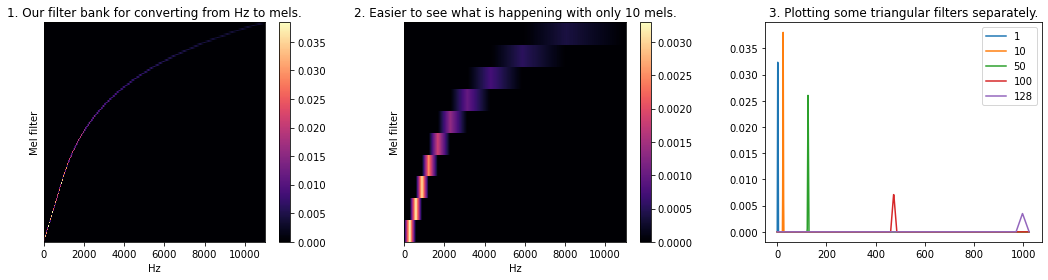

In [ ]:
#The Mel Scale
n_mels = 128
mel = librosa.filters.mel(sr=sample_rate, n_fft=n_fft, n_mels=n_mels)

plt.figure(figsize=(15, 4));
#subplot(nrows, ncols, index)
plt.subplot(1, 3, 1);
librosa.display.specshow(mel, sr=sample_rate, hop_length=hop_length, x_axis='linear');
plt.ylabel('Mel filter');
plt.colorbar();
plt.title('1. Our filter bank for converting from Hz to mels.');

plt.subplot(1, 3, 2);
mel_10 = librosa.filters.mel(sr=sample_rate, n_fft=n_fft, n_mels=10)
librosa.display.specshow(mel_10, sr=sample_rate, hop_length=hop_length, x_axis='linear');
plt.ylabel('Mel filter');
plt.colorbar();
plt.title('2. Easier to see what is happening with only 10 mels.');

plt.subplot(1, 3, 3);
idxs_to_plot = [0, 9, 49, 99, 127]
for i in idxs_to_plot:
    plt.plot(mel[i]);
plt.legend(labels=[f'{i+1}' for i in idxs_to_plot]);
plt.title('3. Plotting some triangular filters separately.');

plt.tight_layout();

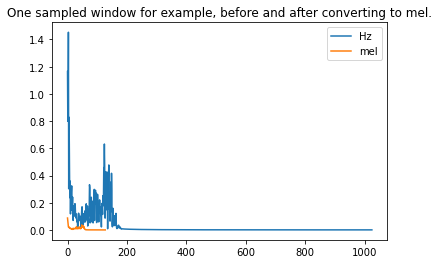

In [ ]:
plt.plot(D[:, 1]);
plt.plot(mel.dot(D[:, 1]));
plt.legend(labels=['Hz', 'mel']);
plt.title('One sampled window for example, before and after converting to mel.');

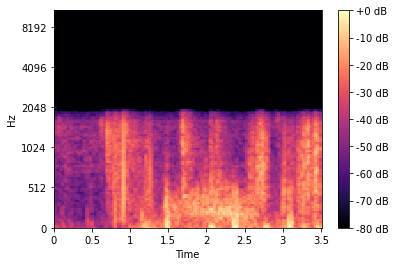

In [ ]:
#The Mel Spectrogram

S = librosa.feature.melspectrogram(signal, sr=sample_rate, n_fft=n_fft, hop_length=hop_length, n_mels=n_mels)
S_DB = librosa.power_to_db(S, ref=np.max)
librosa.display.specshow(S_DB, sr=sample_rate, hop_length=hop_length, x_axis='time', y_axis='mel');
plt.colorbar(format='%+2.0f dB');